In [1]:
library(GenomicRanges, quietly = TRUE)
library(S4Vectors, quietly = TRUE)
library(data.table, quietly = TRUE)


Attaching package: 'BiocGenerics'


The following objects are masked from 'package:stats':

    IQR, mad, sd, var, xtabs


The following objects are masked from 'package:base':

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, intersect, is.unsorted, lapply, Map, mapply,
    match, mget, order, paste, pmax, pmax.int, pmin, pmin.int,
    Position, rank, rbind, Reduce, rownames, sapply, setdiff, table,
    tapply, union, unique, unsplit, which.max, which.min



Attaching package: 'S4Vectors'


The following object is masked from 'package:utils':

    findMatches


The following objects are masked from 'package:base':

    expand.grid, I, unname



Attaching package: 'IRanges'


The following object is masked from 'package:grDevices':

    windows



Attaching package: 'data.table'


The following object is masked from 'package:GenomicRanges':

    shift


The following object is

In [2]:
view_rds <- function(file_path) {
  obj <- readRDS(file_path)
  try(
    print(head(obj))
  )
  try(
    print(length(obj))
  )
  return(obj)
}

In [3]:
view_rda <- function(file_path) {
  var <- load(file_path)
  var <- var[1]
  cat("\n=== ", var, " ===\n")
  cat("Class:", class(get(var)), "\n")
  cat("Type:", typeof(get(var)), "\n")
  try(
    print(head(get(var)))
  )
  try(
    print(length(get(var)))
  )
  return(get(var))
}

In [4]:
view_bed <- function(file_path) {
    dt <- fread(file_path)
    print(head(dt))
    print(nrow(dt))
}

In [5]:
bed_to_GRanges <- function(bed_path, keep_col, col_name = NULL, rds_path = NULL, save = TRUE) {
    dt <- fread(bed_path, header = FALSE)
    colnames(dt) <- paste0("V", seq_len(ncol(dt)))
    if (is.character(keep_col)) {
        meta_idx <- match(keep_col, colnames(dt))
    } else {
        meta_idx <- keep_col
    }
    meta_dt <- dt[, ..meta_idx]
    if (!is.null(col_name)) {
        if (length(col_name) != ncol(meta_dt)) {
            stop("The length of `col_name` doesnt't match the length of `keep_col`")
        }
        setnames(meta_dt, col_name)
    }
    gr <- GRanges(seqnames = dt$V1, ranges = IRanges(start = dt$V2 + 1, end = dt$V3))
    mcols(gr) <- as.data.frame(meta_dt)
    if (is.null(rds_path)) {
        rds_path <- paste0(basename(bed_path), ".rds")
    }
    if (save) {
        saveRDS(gr, rds_path)
    }
    return(gr)
}

In [ ]:
check_overlap <- function(gr1, gr2) {
  gene_hits <- findOverlaps(gr1, gr2)
  if (length(gene_hits) > 0) {
    cat(sprintf("Found %d overlapping pairs\n", length(gene_hits)))
  } else {
    cat("No overlapping found\n")
  }
}

check_self_overlap <- function(gr) {
  stopifnot(inherits(gr, "GRanges"))
  hits <- GenomicRanges::findOverlaps(gr, gr)
  hits <- hits[queryHits(hits) != subjectHits(hits)]
  if (length(hits) > 0) {
    cat(sprintf(
      "Found %d internal overlapping interval pairs\n",
      length(hits)
    ))
  } else {
    cat("No internal overlaps found\n")
  }
}

### cCRE

In [4]:
ccre_library <- view_rds("ENCODE_cCRE_v4_hg38.rds")

GRanges object with 6 ranges and 1 metadata column:
      seqnames      ranges strand |  ccre_class
         <Rle>   <IRanges>  <Rle> | <character>
  [1]     chr1 10034-10250      * |        pELS
  [2]     chr1 10386-10713      * |        pELS
  [3]     chr1 16098-16381      * |     CA-CTCF
  [4]     chr1 17344-17642      * |       CA-TF
  [5]     chr1 29321-29517      * |          CA
  [6]     chr1 66351-66509      * |          CA
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths
[1] 2348854


In [5]:
unique(mcols(ccre_library)$ccre_class)

[1] "pELS"       "CA-CTCF"    "CA-TF"      "CA"         "dELS"      
[6] "TF"         "CA-H3K4me3" "PLS"

## RepeatMasker
### Step 1: Download from RepeatMasker website

In [ ]:
urls <- c("https://www.repeatmasker.org/genomes/hg38/rmsk4.0.5_rb20140131/hg38.fa.out.gz", "https://www.repeatmasker.org/genomes/mm10/rmsk4.0.5_rb20140131/mm10.fa.out.gz") 

for (url in urls) {
  ref <- if (grepl("hg38", url)) {
    "hg38"
  } else if (grepl("mm10", url)) {
    "mm10"
  } else {
    stop("Unknown genome in url: ", url)
  }
  
  temp_file <- tempfile(fileext = ".out.gz")
  curl::curl_download(url, temp_file, quiet = FALSE)

  message("Parsing data...")
  all_lines <- readLines(temp_file, warn = FALSE)
  all_lines <- all_lines[nzchar(trimws(all_lines))] 
  data_start_idx <- which(!grepl("^[A-Za-z]", trimws(all_lines)))[1]
  data_lines <- trimws(all_lines[data_start_idx:length(all_lines)])

  mat <- stringr::str_split(data_lines, "\\s+", simplify = TRUE)
  df <- as.data.frame(mat, stringsAsFactors = FALSE)
  colnames(df) <- paste0("X", seq_len(ncol(df)))

  df$strand <- if ("X9" %in% colnames(df)) {
    ifelse(df$X9 == "C", "-", ifelse(df$X9 == "+", "+", "*"))
  } else {
    rep("*", nrow(df))
  }

  gr <- GenomicRanges::makeGRangesFromDataFrame(
    df, keep.extra.columns = FALSE,
    seqnames.field = "X5", start.field = "X6", end.field = "X7", strand.field = "strand"
  )

  mcols(gr) <- S4Vectors::DataFrame(
    score    = as.integer(df$X1),
    perc_div = as.numeric(df$X2),
    perc_del = as.numeric(df$X3),
    perc_ins = as.numeric(df$X4),
    rep_name  = df$X10,
    rep_class = df$X11
  )

  out_path <- sprintf("RepeatMasker_%s.rds", ref)
  saveRDS(gr, file = out_path, compress = "xz")
  unlink(temp_file)
}

### Step 2: Deal with overlap
For each set of overlapping RepeatMasker annotations, the regions are first split into non-overlapping genomic segments. For each segment, a single representative repeat is selected by prioritizing the highest alignment `score`, followed by the lowest `percent divergence`, and then the largest genomic span as a tie-breaker. 
  
**note**: RepeatMasker annotations do not contain overlaps between elements on opposite strands, so the following function can be safely used to merge regions.

In [ ]:
rm_make_nonoverlap <- function(gr, BPPARAM = SerialParam()) {
    pieces <- disjoin(gr, with.revmap = TRUE)
    rev <- mcols(pieces)$revmap
    cat("Processing", length(pieces), "pieces\n")

    rev_lengths <- lengths(rev)
    needs_selection <- which(rev_lengths > 1)
    no_selection <- which(rev_lengths == 1)
    cat("  -", length(no_selection), "pieces with unique mapping\n")
    cat("  -", length(needs_selection), "pieces need selection\n")

    picked_idx <- integer(length(pieces))
    picked_idx[no_selection] <- unlist(rev[no_selection])
    
    if (length(needs_selection) > 0 ) {
        gr_score <- as.numeric(mcols(gr)$score)
        gr_perc_div <- as.numeric(mcols(gr)$perc_div)
        gr_width <- width(gr)

        n_workers <- BiocParallel::bpnworkers(BPPARAM)
        batch_size <- ceiling(length(needs_selection) / n_workers)
        batches <- split(needs_selection, ceiling(seq_along(needs_selection) / batch_size))
        cat("  Using parallel processing with", n_workers, "workers\n")

        process_batch <- function(batch_indices) {
            result <- integer(length(batch_indices))
            for (i in seq_along(batch_indices)) {
                idx <- rev[[batch_indices[i]]]
                o <- order(-gr_score[idx], gr_perc_div[idx], -gr_width[idx])
                result[i] <- idx[o[1]]
            }
            result
        }
        batch_results <- bplapply(batches, process_batch, BPPARAM = BPPARAM)
        picked_idx[needs_selection] <- unlist(batch_results)
    }
    mcols(pieces)$rep_name <- mcols(gr)$rep_name[picked_idx]
    mcols(pieces)$rep_class <- mcols(gr)$rep_class[picked_idx]

    pieces <- sort(pieces)
    n <- length(pieces)
    if (n > 1) {
        pos_match <- end(pieces)[-n] + 1 == start(pieces)[-1]
        name_match <- mcols(pieces)$rep_name[-n] == mcols(pieces)$rep_name[-1]
        can_merge <- pos_match & name_match

        if (any(can_merge)) {
            cat("  Found", sum(can_merge), "pairs to merge\n")

            block_starts <- c(TRUE, !can_merge)
            first_idx <- which(block_starts)
            last_idx <- c(first_idx[-1] - 1, n)

            pieces <- GRanges(
                seqnames = seqnames(pieces)[first_idx],
                ranges = IRanges(
                    start = start(pieces)[first_idx],
                    end = end(pieces)[last_idx]
                ),
                strand = strand(pieces)[first_idx],
                rep_name = mcols(pieces)$rep_name[first_idx],
                rep_class = mcols(pieces)$rep_class[first_idx]
            )
            cat("  After merging:", length(pieces), "regions\n")
        }
    }
    pieces
}

rm_process <- function(input_rds, output_rds = NULL, BPPARAM = SerialParam()) {
    if (is.null(output_rds)) {
        output_rds <- sub("\\.rds$", "_all_processed.rds", input_rds)
    }
    cat("\n=== Processing", input_rds, "===\n")
    gr <- readRDS(input_rds)
    gr_new <- rm_make_nonoverlap(gr, BPPARAM = BPPARAM)
    saveRDS(gr_new, file = output_rds, compress = "xz")
    cat("Saving to", output_rds, "\n")
}

In [ ]:
n_cores <- as.integer(Sys.getenv("SLURM_CPUS_PER_TASK", "1"))
cat("Using", n_cores, "cores\n")

if (.Platform$OS.type == "unix") {
  BPPARAM <- MulticoreParam(workers = n_cores)
} else {
  BPPARAM <- SnowParam(workers = n_cores)
}

rds_files <- c("RepeatMasker_hg38.rds", "RepeatMasker_mm10.rds")

for (rds in rds_files) {
    rm_process(rds, BPPARAM = BPPARAM)
}

### Step 3: Class Filtering

RepeatMasker annotations contain hierarchical classifications (e.g., `LINE/L1`, `SINE/Alu`) 
and uncertainty markers (`?`). The classes are simplified by:
1. Extracting the main repeat class (removes subclass after "/")
2. Reassigning uncertain annotations (those with "?") to "Unknown"

**The orignal repeat classes include:**  

 [1] "Simple_repeat"     "Satellite/telo"    "LINE/L1"          
 [4] "DNA/hAT-Charlie"   "SINE/MIR"          "LINE/L2"          
 [7] "LINE/CR1"          "LTR/ERVL-MaLR"     "SINE/Alu"         
[10] "DNA/hAT"           "LTR/ERVL"          "LTR"              
[13] "LTR/ERV1"          "DNA/hAT-Tip100"    "Low_complexity"   
[16] "DNA/TcMar-Tigger"  "LTR/ERVL?"         "LTR/ERV1?"        
[19] "LINE/RTE-X"        "LTR?"              "Retroposon/SVA"   
[22] "LTR/ERVK"          "snRNA"             "DNA/MULE-MuDR"    
[25] "tRNA"              "DNA?"              "LTR/Gypsy"        
[28] "DNA/hAT-Blackjack" "Unknown"           "Satellite"        
[31] "DNA/hAT-Tag1"      "srpRNA"            "DNA/hAT-Ac"       
[34] "rRNA"              "DNA/TcMar-Tc2"     "SINE/tRNA-Deu"    
[37] "LINE/RTE-BovB"     "scRNA"             "SINE/5S-Deu-L2"   
[40] "DNA/PiggyBac"      "DNA/hAT?"          "DNA"              
[43] "DNA/TcMar-Mariner" "RC/Helitron"       "LTR/Gypsy?"       
[46] "DNA/hAT-Tip100?"   "SINE/tRNA-RTE"     "SINE/tRNA"        
[49] "LINE/Jockey"       "LINE/Penelope"     "LINE/Dong-R4"     
[52] "DNA/TcMar-Tc1"     "RNA"               "DNA/Kolobok"      
[55] "DNA/TcMar"         "Satellite/centr"   "RC?/Helitron?"    
[58] "DNA?/hAT-Tip100?"  "DNA?/PiggyBac?"    "DNA/Merlin"       
[61] "DNA/TcMar-Pogo"    "LINE/L1-Tx1"       "DNA/TcMar?"       
[64] "DNA/PIF-Harbinger" "SINE?/tRNA"        "Satellite/acro"  

In [ ]:
rm_filter_main_classes <- function(input_rds, output_rds = NULL) {
    if (is.null(output_rds)) {
        output_rds <- sub("_all_processed\\.rds$", "_processed.rds", input_rds)
    }
    
    cat("\n=== Filtering", input_rds, "===\n")
    gr <- readRDS(input_rds)
    cat("  Original regions:", length(gr), "\n")
    
    main_class <- sub("/.*", "", gr$rep_class) 
    has_question <- grepl("\\?", main_class)
    cat("  Regions with '?' reassigned to 'Unknown':", sum(has_question), 
        "(", round(mean(has_question)*100, 2), "%)\n")
    main_class[has_question] <- "Unknown"
    gr$rep_class <- main_class
    
    cat("  Processed regions:", length(gr), "\n")
    saveRDS(gr, file = output_rds, compress = "xz")
    cat("  Saved to:", output_rds, "\n")

    cat("\n  Final class distribution:\n")
    class_table <- sort(table(gr$rep_class), decreasing = TRUE)
    print(class_table)
}

In [ ]:
suppressPackageStartupMessages({
  library(GenomicRanges)
})

rds_files <- c("RepeatMasker_hg38_all_processed.rds", "RepeatMasker_mm10_all_processed.rds")
for (rds in rds_files) {
  rm_filter_main_classes(rds)
}

### ChromHMM

In [25]:
view_bed("mm10_100_segments_segments.bed")

       V1      V2      V3          V4
   <char>   <int>   <int>      <char>
1:  chr10       0 3100000 1_mGapArtf1
2:  chr10 3100000 3100400    15_mHET9
3:  chr10 3100400 3100800 1_mGapArtf1
4:  chr10 3100800 3101200    15_mHET9
5:  chr10 3101200 3101400    12_mHET6
6:  chr10 3101400 3102200    13_mHET7
[1] 5929546


In [11]:
gr <- bed_to_GRanges(bed_path = "mm10_100_segments_segments.bed", keep_col = 4, col_name = "V4", rds_path = "ChromHMM_mm10.rds", save = FALSE)

In [12]:
x <- mcols(gr)$V4
x <- gsub("^\\d+", "", x)
x <- gsub("\\d+$", "", x)
x <- gsub("_", "", x)
x <- gsub("^m", "", x)
mcols(gr)$clean_class <- x
print(head(gr))
print(unique(mcols(gr)$clean_class))

GRanges object with 6 ranges and 2 metadata columns:
      seqnames          ranges strand |          V4 clean_class
         <Rle>       <IRanges>  <Rle> | <character> <character>
  [1]    chr10       1-3100000      * | 1_mGapArtf1     GapArtf
  [2]    chr10 3100001-3100400      * |    15_mHET9         HET
  [3]    chr10 3100401-3100800      * | 1_mGapArtf1     GapArtf
  [4]    chr10 3100801-3101200      * |    15_mHET9         HET
  [5]    chr10 3101201-3101400      * |    12_mHET6         HET
  [6]    chr10 3101401-3102200      * |    13_mHET7         HET
  -------
  seqinfo: 66 sequences from an unspecified genome; no seqlengths
 [1] "GapArtf"     "HET"         "TxEx"        "Quies"       "OpenC"      
 [6] "EnhWk"       "EnhA"        "ReprPC"      "ReprPCopenC" "BivProm"    
[11] "PromF"       "TSS"         "TxWk"        "ZNF"         "Tx"         
[16] "TxEnh"      


In [13]:
chromhmm_mm10_class <- unique(mcols(gr)$clean_class)
chromhmm_mm10_class

[1] "GapArtf"     "HET"         "TxEx"        "Quies"       "OpenC"      
 [6] "EnhWk"       "EnhA"        "ReprPC"      "ReprPCopenC" "BivProm"    
[11] "PromF"       "TSS"         "TxWk"        "ZNF"         "Tx"         
[16] "TxEnh"

In [5]:
chromhmm_hg38 <- view_rds("ChromHMM_hg38.rds")

GRanges object with 6 ranges and 2 metadata columns:
      seqnames      ranges strand |          V4 clean_class
         <Rle>   <IRanges>  <Rle> | <character> <character>
  [1]     chr1 10000-10400      * |  2_GapArtf2     GapArtf
  [2]     chr1 10400-10600      * |    27_Acet1        Acet
  [3]     chr1 10600-10800      * |   38_EnhWk4       EnhWk
  [4]     chr1 10800-12800      * |  1_GapArtf1     GapArtf
  [5]     chr1 12800-13000      * |   38_EnhWk4       EnhWk
  [6]     chr1 13000-13200      * |   37_EnhWk3       EnhWk
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths
[1] 6096307


In [7]:
chromhmm_hg38_class <- unique(mcols(chromhmm_hg38)$clean_class)

In [14]:
chromhmm_class <- unique(c(chromhmm_hg38_class, chromhmm_mm10_class))
print(chromhmm_class)

 [1] "GapArtf"     "Acet"        "EnhWk"       "Quies"       "TxWk"       
 [6] "TxEx"        "EnhA"        "ReprPC"      "HET"         "DNase"      
[11] "PromF"       "Tx"          "TSS"         "znf"         "TxEnh"      
[16] "BivProm"     "OpenC"       "ReprPCopenC" "ZNF"        


In [15]:
setdiff(chromhmm_class, chromhmm_hg38_class)

[1] "OpenC"       "ReprPCopenC" "ZNF"

In [16]:
setdiff(chromhmm_class, chromhmm_mm10_class)

[1] "Acet"  "DNase" "znf"

In [19]:
library(dplyr)

chromhmm_hg38$clean_class <- recode(
  chromhmm_hg38$clean_class,
  "znf"   = "ZNF",
  "DNase" = "OpenC"
)
chromhmm_hg38_class <- unique(mcols(chromhmm_hg38)$clean_class)
chromhmm_class <- unique(c(chromhmm_hg38_class, chromhmm_mm10_class))
print(chromhmm_class)


Attaching package: 'dplyr'


The following objects are masked from 'package:data.table':

    between, first, last


The following objects are masked from 'package:GenomicRanges':

    intersect, setdiff, union


The following object is masked from 'package:GenomeInfoDb':

    intersect


The following objects are masked from 'package:IRanges':

    collapse, desc, intersect, setdiff, slice, union


The following objects are masked from 'package:S4Vectors':

    first, intersect, rename, setdiff, setequal, union


The following objects are masked from 'package:BiocGenerics':

    combine, intersect, setdiff, union


The following objects are masked from 'package:stats':

    filter, lag


The following objects are masked from 'package:base':

    intersect, setdiff, setequal, union




 [1] "GapArtf"     "Acet"        "EnhWk"       "Quies"       "TxWk"       
 [6] "TxEx"        "EnhA"        "ReprPC"      "HET"         "OpenC"      
[11] "PromF"       "Tx"          "TSS"         "ZNF"         "TxEnh"      
[16] "BivProm"     "ReprPCopenC"


In [22]:
chromhmm_hg38 <- chromhmm_hg38[chromhmm_hg38$clean_class != "GapArtf"]
chromhmm_mm10 <- gr[gr$clean_class != "GapArtf"]

In [27]:
saveRDS(chromhmm_hg38, "ChromHMM_hg38.rds", compress = "xz")
saveRDS(chromhmm_mm10, "ChromHMM_mm10.rds", compress = "xz")

## GENCODE

### Step 1: Gene-level filtering
Before selecting representative transcripts, genes are filtered to exclude categories that typically lack RNA transcripts. The following gene types are removed:

- **Pseudogenes**: `processed_pseudogene`, `unprocessed_pseudogene`, `unitary_pseudogene`, `rRNA_pseudogene`
- **Immunoglobulin and T-cell receptor pseudogenes**: `IG_V_pseudogene`, `IG_J_pseudogene`, `IG_C_pseudogene`, `TR_V_pseudogene`, `TR_J_pseudogene`, `IG_pseudogene`
- **Artifacts**: `artifact`

After this filtering step:
- **hg38**: 66,413 genes remain (from 78,691 original genes)
- **mm10**: 42,396 genes remain (from 55,335 original genes)


### Step 2: Transcript validation and evidence levels
In the original `basic.annotation.CHR` GTF files, each gene is associated with at least one transcript, and many genes have multiple transcripts.
- **hg38**: Among 66,413 filtered genes, 27,976 genes have more than one annotated transcript.   
- **mm10**: Among 42,396 filtered genes, 13,887 genes have more than one annotated transcript.   

Not all annotated transcripts are experimentally validated. GENCODE integrates evidence from multiple sources, and the presence of a transcript in the annotation does not necessarily imply direct experimental confirmation. Several annotation fields are commonly used to assess transcript reliability and representativeness:
- `tag ∈ {MANE_Select, appris_principal_1–4}`  
  These tags indicate that a transcript is designated as a representative or principal isoform under the MANE or APPRIS frameworks, and is often used as a standardized reference for functional or comparative analyses.
- `transcript_support_level`  
  This field reflects the degree of support from mRNA and EST alignment evidence. Lower values correspond to stronger transcriptional support.
- `havana_transcript`  
  This annotation indicates that the transcript originates from the HAVANA manual curation pipeline, implying human expert review and integration rather than purely automated prediction.

When a single representative transcript per gene is required, transcripts can be prioritized according to the following hierarchy:

1. MANE_Select  
2. appris_principal_1  
3. appris_principal_2  
4. appris_principal_3  
5. appris_principal_4  
6. Presence of a defined `transcript_support_level`  
7. Presence of `havana_transcript`

- **hg38**: 46,922 of 66,413 genes have at least one 'validated' transcript
- **mm10**: 42,393 of 42,396 genes have at least one 'validated' transcript


=== Processing: gencode.v49.basic.annotation.CHR.hg38.gtf ===  
Original Gene Number: 78691   
Original transcripts: 280000   
Number of genes after filtering gene type: 66413   
Number of genes with multi transcripts: 27976   
Number of genes with at least one validated transcript: 46922   
Final transcript number: 46922   
Found 23500 overlapping gene pairs  

=== Processing: gencode.vM23.basic.annotation.CHR.mm10.gtf ===   
Original Gene Number: 55335  
Original transcripts: 81596   
Number of genes after filtering gene type: 42396  
Number of genes with multi transcripts: 13887  
Number of genes with at least one validated transcript: 42393  
Final transcript number: 42393  
Found 13862 overlapping gene pairs  

In [11]:
suppressPackageStartupMessages({
  library(rtracklayer)
  library(IRanges)
  library(R.utils)
  library(data.table)
  library(glue)
  library(parallel)
  library(BiocParallel)
})

In [ ]:
# Unzip
gtf_gz_list <- c("gencode.v49.basic.annotation.CHR.hg38.gtf.gz", 
                 "gencode.v49.basic.annotation.CHR.mm10.gtf.gz")

for (gtf_gz in gtf_gz_list) {
  message("Loop sees gtf_gz = ", gtf_gz)
  gtf <- gunzip(gtf_gz, destname = sub("\\.gz$", "", gtf_gz),
                     remove = FALSE, overwrite = TRUE)
}

In [ ]:
gtf <- "gencode.v49.basic.annotation.CHR.hg38.gtf"
gr_hg38 <- import(gtf)
head(gr_hg38)

GRanges object with 6 ranges and 22 metadata columns:
      seqnames      ranges strand |   source       type     score     phase
         <Rle>   <IRanges>  <Rle> | <factor>   <factor> <numeric> <integer>
  [1]     chr1 11121-24894      + |   HAVANA gene              NA      <NA>
  [2]     chr1 11426-14409      + |   HAVANA transcript        NA      <NA>
  [3]     chr1 11426-11671      + |   HAVANA exon              NA      <NA>
  [4]     chr1 12010-12227      + |   HAVANA exon              NA      <NA>
  [5]     chr1 12613-12721      + |   HAVANA exon              NA      <NA>
  [6]     chr1 13221-14409      + |   HAVANA exon              NA      <NA>
                gene_id   gene_type   gene_name       level                 tag
            <character> <character> <character> <character>         <character>
  [1] ENSG00000290825.2      lncRNA    DDX11L16           2 overlaps_pseudogene
  [2] ENSG00000290825.2      lncRNA    DDX11L16           2              TAGENE
  [3] ENSG00000290

In [ ]:
unique(mcols(gr_hg38)$type)

[1] gene           transcript     exon           CDS            start_codon   
[6] stop_codon     UTR            Selenocysteine
8 Levels: gene transcript exon CDS start_codon stop_codon ... Selenocysteine

In [ ]:
unique(mcols(gr_hg38)$tag)

[1] "overlaps_pseudogene"            "TAGENE"                        
 [3] NA                               "GENCODE_Primary"               
 [5] "overlapping_locus"              "ncRNA_host"                    
 [7] "basic"                          "CCDS"                          
 [9] "pseudo_consens"                 "readthrough_transcript"        
[11] "exp_conf"                       "appris_alternative_2"          
[13] "appris_alternative_1"           "retrogene"                     
[15] "appris_principal_2"             "appris_principal_4"            
[17] "confirm_experimentally"         "readthrough_gene"              
[19] "appris_principal_1"             "reference_genome_error"        
[21] "appris_principal_5"             "seleno"                        
[23] "stop_codon_readthrough"         "MANE_Plus_Clinical"            
[25] "appris_principal_3"             "MANE_Select"                   
[27] "polymorphic_pseudogene_no_stop" "fragmented_locus"              
[29] "fragmented_mixed_strand_locus"  "Selenoprotein"                 
[31] "semi_processed"                 "EnsEMBL_merge_exception"       
[33] "precursor_RNA"                  "artifactual_duplication"

In [ ]:
gtf <- "gencode.vM23.basic.annotation.CHR.mm10.gtf.gz"
gr_mm10 <- import(gtf)
head(gr_mm10)
unique(mcols(gr_mm10)$type)

In [ ]:
# gene:transcript = 1:1
# Select one representative transcript per gene based on evidence hierarchy
suppressPackageStartupMessages({
  library(rtracklayer)
  library(GenomicRanges)
  library(glue)
})

gtf_list <- c(
  "gencode.v49.basic.annotation.CHR.hg38.gtf", 
  "gencode.vM23.basic.annotation.CHR.mm10.gtf"
)

gene_type_no_tx <- c(
  "processed_pseudogene", "unprocessed_pseudogene", "unitary_pseudogene",
  "rRNA_pseudogene", "IG_V_pseudogene", "IG_J_pseudogene", "IG_C_pseudogene",
  "TR_V_pseudogene", "TR_J_pseudogene", "IG_pseudogene", "artifact"
)

priority_tags <- c(
  "MANE_Select", "appris_principal_1", "appris_principal_2",
  "appris_principal_3", "appris_principal_4"
)

for (gtf in gtf_list) {
  # Parse reference info
  prefix <- tools::file_path_sans_ext(basename(gtf))
  if (grepl("hg38", prefix)) {
    ref <- "hg38"
    version <- "v49"
  } else if (grepl("mm10", prefix)) {
    ref <- "mm10"
    version <- "vM23"
  } else {
    warning(sprintf("Unknown reference in filename: %s, skipping...\n", gtf))
    next
  }
  
  cat("\nProcessing:", gtf, "\n")
  
  # Import GTF
  gr <- import(gtf)
  tx <- gr[gr$type == "transcript" & !is.na(gr$gene_id)]
  gene_n <- length(unique(tx$gene_id))
  cat("Original Gene Number:", gene_n, "\n")
  cat("Original transcripts:", length(tx), "\n")
  
  # Filter by gene type
  gene_gr <- gr[gr$type == "gene" & !gr$gene_type %in% gene_type_no_tx]
  valid_gene_id <- unique(gene_gr$gene_id)
  gr <- gr[is.na(gr$gene_id) | gr$gene_id %in% valid_gene_id]
  tx <- gr[gr$type == "transcript"]
  cat("Number of genes after filtering gene type:", length(valid_gene_id), "\n")
  
  # Count multi-transcript genes
  gene_count <- table(tx$gene_id)
  dup_n <- sum(gene_count > 1)
  cat("Number of genes with multi transcripts:", dup_n, "\n")
  
  # Filter for evidence-based transcripts
  tx <- tx[
    !is.na(tx$havana_transcript) |
    !is.na(tx$transcript_support_level) |
    tx$tag %in% priority_tags
  ]
  pass_gene_id <- unique(tx$gene_id)
  gr <- gr[is.na(gr$gene_id) | gr$gene_id %in% pass_gene_id]
  cat("Number of genes with at least one validated transcript:", length(pass_gene_id), "\n")
  
  # Rank transcripts
  tx$rank <- NA_integer_
  tx$rank[tx$tag == "MANE_Select"] <- 1L
  is_appris <- grepl("^appris_principal_[1-4]$", tx$tag)
  tx$rank[is_appris] <- 1L + as.integer(sub("appris_principal_", "", tx$tag[is_appris]))
  tx$rank[is.na(tx$rank) & !is.na(tx$transcript_support_level)] <- 6L
  tx$rank[is.na(tx$rank) & !is.na(tx$havana_transcript)] <- 7L
  
  # Select best transcript per gene
  tx <- tx[order(tx$gene_id, tx$rank)]
  tx <- tx[!duplicated(tx$gene_id)]
  keep_transcript_id <- tx$transcript_id
  cat("Final transcript number:", length(keep_transcript_id), "\n")
  
  # Create final output
  gr_new <- gr[is.na(gr$transcript_id) | gr$transcript_id %in% keep_transcript_id]
  output_file <- glue("GENCODE_{version}_{ref}_single_tx_by_evidence.rds")
  saveRDS(gr_new, output_file, compress = "xz")
  
  # Check for overlapping genes
  gene_gr <- gr_new[gr_new$type == "gene"]
  gene_hits <- findOverlaps(gene_gr, gene_gr)
  gene_hits <- gene_hits[queryHits(gene_hits) != subjectHits(gene_hits)]
  if (length(gene_hits) > 0) {
    cat(sprintf("Found %d overlapping gene pairs\n", length(gene_hits)))
  } else {
    cat("No overlapping genes found\n")
  }
}

In [ ]:
gtf_list <- c("GENCODE_v49_hg38_single_tx_by_evidence.rds","GENCODE_vM23_mm10_single_tx_by_evidence.rds")

for (gtf in gtf_list) {
  prefix <- tools::file_path_sans_ext(basename(gtf))
  cat("==== Processing", prefix, "====\n")
  gr <- readRDS(gtf)
  gene_gr <- gr[gr$type == "gene"]
  gene_table <- sort(table(gene_gr$gene_type), decreasing = TRUE)
  print(gene_table)
}

**GENCODE v49 hg38 (single transcript per gene, by evidence)**
| Gene type | Count |
|-----------|-------|
| protein_coding | 20036 |
| lncRNA | 15490 |
| misc_RNA | 2206 |
| snRNA | 1901 |
| miRNA | 1879 |
| transcribed_unprocessed_pseudogene | 1569 |
| transcribed_processed_pseudogene | 1144 |
| TEC | 1015 |
| snoRNA | 941 |
| transcribed_unitary_pseudogene | 191 |
| IG_V_gene | 146 |
| TR_V_gene | 107 |
| TR_J_gene | 79 |
| scaRNA | 49 |
| rRNA | 46 |
| IG_D_gene | 37 |
| Mt_tRNA | 22 |
| IG_J_gene | 18 |
| IG_C_gene | 14 |
| ribozyme | 8 |
| TR_C_gene | 6 |
| sRNA | 5 |
| TR_D_gene | 5 |
| vault_RNA | 4 |
| Mt_rRNA | 2 |
| translated_processed_pseudogene | 2 |

**GENCODE vM23 mm10 (single transcript per gene, by evidence)**

| Gene type | Count |
|-----------|-------|
| protein_coding | 21848 |
| lncRNA | 9963 |
| TEC | 3238 |
| miRNA | 2202 |
| snoRNA | 1507 |
| snRNA | 1383 |
| misc_RNA | 562 |
| rRNA | 354 |
| transcribed_processed_pseudogene | 301 |
| transcribed_unprocessed_pseudogene | 268 |
| IG_V_gene | 218 |
| TR_V_gene | 144 |
| polymorphic_pseudogene | 88 |
| TR_J_gene | 70 |
| pseudogene | 58 |
| scaRNA | 51 |
| transcribed_unitary_pseudogene | 23 |
| Mt_tRNA | 22 |
| ribozyme | 22 |
| IG_D_gene | 19 |
| IG_J_gene | 14 |
| IG_C_gene | 13 |
| TR_C_gene | 8 |
| IG_LV_gene | 4 |
| TR_D_gene | 4 |
| IG_D_pseudogene | 3 |
| Mt_rRNA | 2 |
| sRNA | 2 |
| scRNA | 1 |
| translated_unprocessed_pseudogene | 1 |


### Step 3: Extract Promoter, Intron & UTR

In [19]:
process_gtf <- function(gr, BPPARAM = SerialParam()) {
  exon_gr <- gr[gr$type == "exon"]
  cds_gr  <- gr[gr$type == "CDS"]
  utr_gr <- gr[gr$type == "UTR"]
  transcript_gr <- gr[gr$type == "transcript"]
  metadata_cols <- setdiff(colnames(mcols(gr)), c("type", "transcript_id"))

  # Extract promoters (1kb upstream of TSS)
  promoter_upstream = 1000
  promoter_list <- bplapply(seq_along(transcript_gr), function(i) {
    tx <- transcript_gr[i]
    if (as.character(strand(tx)) == "+") {
      prom_start <- max(1, start(tx) - promoter_upstream)
      prom_end <- start(tx) - 1
    } else if (as.character(strand(tx)) == "-") {
      prom_start <- end(tx) + 1
      prom_end <- end(tx) + promoter_upstream
    } else {
      return(NULL)
    }
    if (prom_end < prom_start) return(NULL)
    GRanges(
      seqnames = seqnames(tx),
      ranges = IRanges(start = prom_start, end = prom_end),
      strand = strand(tx),
      transcript_id = tx$transcript_id
    )
  }, BPPARAM = BPPARAM)

  promoter_list <- promoter_list[!vapply(promoter_list, is.null, logical(1))]
  if (length(promoter_list) > 0) {
    promoter_gr <- unlist(GRangesList(promoter_list), use.names = FALSE)
    promoter_gr$type <- "promoter"
    idx <- match(promoter_gr$transcript_id, transcript_gr$transcript_id)
    mcols(promoter_gr)[, metadata_cols] <- mcols(transcript_gr)[idx, metadata_cols]
  } else {
    promoter_gr <- GRanges()
  }
  
  # Extract introns 
  exon_by_tx <- split(exon_gr, exon_gr$transcript_id)
  intron_list <- bplapply(names(exon_by_tx), function(tx_id) {
    exons <- exon_by_tx[[tx_id]]

    # The transcript span extends from the start of the first exon to the end of the last exon
    # A transcript containing only a single exon has no introns
    if (length(exons) <= 1) {return(NULL)}

    exons <- sort(exons)
    n <- length(exons)
    intron_starts <- end(exons[-n]) + 1
    intron_ends <- start(exons[-1]) - 1

    valid <- intron_ends >= intron_starts
    if (!any(valid)) {return(NULL)}
    GRanges(
      seqnames = seqnames(exons[1]), 
      ranges = IRanges(start = intron_starts[valid], end = intron_ends[valid]), 
      strand = strand(exons[1]),
      transcript_id = tx_id
    )
  }, BPPARAM = BPPARAM)

  names(intron_list) <- names(exon_by_tx)
  intron_list <- intron_list[!vapply(intron_list, is.null, logical(1))]
  
  if (length(intron_list) > 0) {
    intron_gr <- unlist(GRangesList(intron_list), use.names = FALSE)
    intron_gr$type <- "intron"
    idx <- match(intron_gr$transcript_id, transcript_gr$transcript_id)
    mcols(intron_gr)[, metadata_cols] <- mcols(transcript_gr)[idx, metadata_cols]
  } else {
    intron_gr <- GRanges()
  }

  # Divide UTR into 5'UTR and 3'UTR
  utr5_gr <- GRanges()
  utr3_gr <- GRanges()

  cds_by_tx <- split(cds_gr, cds_gr$transcript_id)
  utr_by_tx <- split(utr_gr, utr_gr$transcript_id)
  tx_ids <- intersect(names(cds_by_tx), names(utr_by_tx))

  cds_bounds <- bplapply(cds_by_tx[tx_ids], function(x) {
    list(
      cds_start = min(start(x)),
      cds_end = max(end(x)), 
      strand = as.character(strand(x)[1])
    )
  }, BPPARAM = BPPARAM)

  utr_list <- bplapply(seq_along(tx_ids), function(i) {
    tx_id <- tx_ids[i]
    utr_tx <- utr_by_tx[[tx_id]]
    cds_start <- cds_bounds[[i]]$cds_start
    cds_end <- cds_bounds[[i]]$cds_end
    st <- cds_bounds[[i]]$strand
    
    if (st == "+") {
      utr5 <- utr_tx[end(utr_tx) < cds_start]
      utr3 <- utr_tx[start(utr_tx) > cds_end]
    } else if (st == "-") {
      utr5 <- utr_tx[start(utr_tx) > cds_end]
      utr3 <- utr_tx[end(utr_tx) < cds_start]
    } else {
      utr5 <- GRanges()
      utr3 <- GRanges()
    }

    if (length(utr5) > 0) utr5$transcript_id <- tx_id
    if (length(utr3) > 0) utr3$transcript_id <- tx_id 
    list(utr5 = utr5, utr3 = utr3)
  }, BPPARAM = BPPARAM)

  utr5_list <- lapply(utr_list, `[[`, "utr5")
  utr5_list <- utr5_list[lengths(utr5_list) > 0]
  utr3_list <- lapply(utr_list, `[[`, "utr3")
  utr3_list <- utr3_list[lengths(utr3_list) > 0]

  if (length(utr5_list) > 0) {
    utr5_gr <- unlist(GRangesList(utr5_list), use.names = FALSE)
    utr5_gr$type <- "5' UTR"
    idx <- match(utr5_gr$transcript_id, transcript_gr$transcript_id)
    mcols(utr5_gr)[, metadata_cols] <- mcols(transcript_gr)[idx, metadata_cols]
  }
  if (length(utr3_list) > 0) {
    utr3_gr <- unlist(GRangesList(utr3_list), use.names = FALSE)
    utr3_gr$type <- "3' UTR"
    idx <- match(utr3_gr$transcript_id, transcript_gr$transcript_id)
    mcols(utr3_gr)[, metadata_cols] <- mcols(transcript_gr)[idx, metadata_cols]
  }
  
  # Merge
  gr_out <- c(
    gr[!gr$type %in% c("UTR", "Selenocysteine", "start_codon", "stop_codon")],
    promoter_gr,
    intron_gr,
    utr5_gr,
    utr3_gr
  )
  sort(gr_out)
}

In [17]:
# Gene 1: 简单基因，3个外显子
gene1_tx1 <- GRanges(
  seqnames = "chr1",
  ranges = IRanges(start = 1000, end = 5000),
  strand = "+",
  type = "transcript",
  gene_id = "GENE001",
  transcript_id = "TX001",
  source = "TEST"
)

gene1_exons <- GRanges(
  seqnames = "chr1",
  ranges = IRanges(
    start = c(1000, 2000, 4000),
    end =   c(1500, 2500, 5000)
  ),
  strand = "+",
  type = "exon",
  gene_id = "GENE001",
  transcript_id = "TX001",
  source = "TEST"
)

gene1_cds <- GRanges(
  seqnames = "chr1",
  ranges = IRanges(
    start = c(1200, 2000, 4000),
    end =   c(1500, 2500, 4800)
  ),
  strand = "+",
  type = "CDS",
  gene_id = "GENE001",
  transcript_id = "TX001",
  source = "TEST"
)

gene1_utr <- GRanges(
  seqnames = "chr1",
  ranges = IRanges(
    start = c(1000, 4801),
    end =   c(1199, 5000)
  ),
  strand = "+",
  type = "UTR",
  gene_id = "GENE001",
  transcript_id = "TX001",
  source = "TEST"
)

# Gene 2: 负链基因，2个外显子
gene2_tx1 <- GRanges(
  seqnames = "chr1",
  ranges = IRanges(start = 10000, end = 15000),
  strand = "-",
  type = "transcript",
  gene_id = "GENE002",
  transcript_id = "TX002",
  source = "TEST"
)

gene2_exons <- GRanges(
  seqnames = "chr1",
  ranges = IRanges(
    start = c(10000, 14000),
    end =   c(11000, 15000)
  ),
  strand = "-",
  type = "exon",
  gene_id = "GENE002",
  transcript_id = "TX002",
  source = "TEST"
)

gene2_cds <- GRanges(
  seqnames = "chr1",
  ranges = IRanges(
    start = c(10200, 14000),
    end =   c(11000, 14800)
  ),
  strand = "-",
  type = "CDS",
  gene_id = "GENE002",
  transcript_id = "TX002",
  source = "TEST"
)

gene2_utr <- GRanges(
  seqnames = "chr1",
  ranges = IRanges(
    start = c(10000, 14801),
    end =   c(10199, 15000)
  ),
  strand = "-",
  type = "UTR",
  gene_id = "GENE002",
  transcript_id = "TX002",
  source = "TEST"
)

# Gene 3: 多转录本基因（只测试第一个转录本）
gene3_tx1 <- GRanges(
  seqnames = "chr2",
  ranges = IRanges(start = 5000, end = 10000),
  strand = "+",
  type = "transcript",
  gene_id = "GENE003",
  transcript_id = "TX003",
  source = "TEST"
)

gene3_exons <- GRanges(
  seqnames = "chr2",
  ranges = IRanges(
    start = c(5000, 7000, 9000),
    end =   c(6000, 8000, 10000)
  ),
  strand = "+",
  type = "exon",
  gene_id = "GENE003",
  transcript_id = "TX003",
  source = "TEST"
)

gene3_cds <- GRanges(
  seqnames = "chr2",
  ranges = IRanges(
    start = c(5500, 7000, 9000),
    end =   c(6000, 8000, 9500)
  ),
  strand = "+",
  type = "CDS",
  gene_id = "GENE003",
  transcript_id = "TX003",
  source = "TEST"
)

gene3_utr <- GRanges(
  seqnames = "chr2",
  ranges = IRanges(
    start = c(5000, 9501),
    end =   c(5499, 10000)
  ),
  strand = "+",
  type = "UTR",
  gene_id = "GENE003",
  transcript_id = "TX003",
  source = "TEST"
)

# 合并所有测试数据
test_gr <- c(
  gene1_tx1, gene1_exons, gene1_cds, gene1_utr,
  gene2_tx1, gene2_exons, gene2_cds, gene2_utr,
  gene3_tx1, gene3_exons, gene3_cds, gene3_utr
)

Warning message in .merge_two_Seqinfo_objects(x, y):
"The 2 combined objects have no sequence levels in common. (Use
  suppressWarnings() to suppress this warning.)"


In [21]:
cat("\n\n========== Testing process_gtf ==========\n")
result <- process_gtf(test_gr)

cat("\nResult summary:\n")
print(table(result$type))

cat("\n\n===== Promotors extracted =====\n")
promotors <- result[result$type == "promoter"]
print(promotors)

cat("\n\n===== Introns extracted =====\n")
introns <- result[result$type == "intron"]
print(introns)
cat("TX001 introns (should be 2): ", sum(introns$transcript_id == "TX001"), "\n")
cat("TX002 introns (should be 1): ", sum(introns$transcript_id == "TX002"), "\n")
cat("TX003 introns (should be 2): ", sum(introns$transcript_id == "TX003"), "\n")

cat("\n\n===== 5'UTRs =====\n")
utr5 <- result[result$type == "5' UTR"]
print(utr5)

cat("\n\n===== 3'UTRs =====\n")
utr3 <- result[result$type == "3' UTR"]
print(utr3)




========== Testing process_gtf ==========

Result summary:

    3' UTR     5' UTR        CDS       exon     intron   promoter transcript 
         3          3          8          8          5          3          3 


===== Promotors extracted =====
GRanges object with 3 ranges and 4 metadata columns:
      seqnames      ranges strand |        type     gene_id transcript_id
         <Rle>   <IRanges>  <Rle> | <character> <character>   <character>
  [1]     chr1       1-999      + |    promoter     GENE001         TX001
  [2]     chr1 15001-16000      - |    promoter     GENE002         TX002
  [3]     chr2   4000-4999      + |    promoter     GENE003         TX003
           source
      <character>
  [1]        TEST
  [2]        TEST
  [3]        TEST
  -------
  seqinfo: 2 sequences from an unspecified genome; no seqlengths


===== Introns extracted =====
GRanges object with 5 ranges and 4 metadata columns:
      seqnames      ranges strand |        type     gene_id transcript_id
 

In [ ]:
check_gr <- function(gr) {
  all_tx <- unique(gr$transcript_id[gr$type == "transcript" & !is.na(gr$transcript_id)])
  n_total <- length(all_tx)
  
  cat("=== Transcript Structure Check ===\n")
  cat("Total transcripts:", n_total, "\n\n")
  
  # 1. Check promoter
  tx_with_promoter <- unique(gr$transcript_id[gr$type == "promoter" & !is.na(gr$transcript_id)])
  with_promoter_prop <- length(tx_with_promoter) / n_total
  cat("Transcripts with promoter:\n")
  cat("  Count:", length(tx_with_promoter), "\n")
  cat("  Proportion:", sprintf("%.2f%%", with_promoter_prop * 100), "\n\n")

  # 2. Check intron
  tx_with_intron <- unique(gr$transcript_id[gr$type == "intron" & !is.na(gr$transcript_id)])
  with_intron_prop <- length(tx_with_intron) / n_total
  cat("Transcripts with intron:\n")
  cat("  Count:", length(tx_with_intron), "\n")
  cat("  Proportion:", sprintf("%.2f%%", with_intron_prop * 100), "\n\n")
  
  # 3. Check UTR
  utr_gr <- gr[gr$type %in% c("5' UTR", "3' UTR") & !is.na(gr$transcript_id)]
  
  if (length(utr_gr) > 0) {
    utr_summary <- table(utr_gr$transcript_id, utr_gr$type)
    has_5utr_col <- "5' UTR" %in% colnames(utr_summary)
    has_3utr_col <- "3' UTR" %in% colnames(utr_summary)
    
    if (has_5utr_col && has_3utr_col) {
      has_5utr <- utr_summary[, "5' UTR"] >= 1
      has_3utr <- utr_summary[, "3' UTR"] >= 1
      both_utr <- has_5utr & has_3utr
      single_5utr <- utr_summary[, "5' UTR"] == 1
      single_3utr <- utr_summary[, "3' UTR"] == 1
      complete_utr <- single_5utr & single_3utr
      
      cat("UTR statistics:\n")
      cat("  Transcripts with 5' UTR:", sum(has_5utr), sprintf("(%.2f%%)", mean(has_5utr) * 100), "\n")
      cat("  Transcripts with 3' UTR:", sum(has_3utr), sprintf("(%.2f%%)", mean(has_3utr) * 100), "\n")
      cat("  Transcripts with both UTRs:", sum(both_utr), sprintf("(%.2f%%)", mean(both_utr) * 100), "\n")
      cat("  Transcripts with exactly 1 of each UTR:", sum(complete_utr), sprintf("(%.2f%%)", mean(complete_utr) * 100), "\n")
      
      multi_5utr <- sum(utr_summary[, "5' UTR"] > 1)
      multi_3utr <- sum(utr_summary[, "3' UTR"] > 1)
      if (multi_5utr > 0 || multi_3utr > 0) {
        cat("  WARNING: Multiple UTRs detected:\n")
        if (multi_5utr > 0) cat("    ", multi_5utr, "transcripts with >1 5' UTR\n")
        if (multi_3utr > 0) cat("    ", multi_3utr, "transcripts with >1 3' UTR\n")
      }
    } else {
      cat("UTR statistics: Incomplete UTR data\n")
      if (has_5utr_col) cat("  Only 5' UTR found:", sum(utr_summary[, "5' UTR"]), "transcripts\n")
      if (has_3utr_col) cat("  Only 3' UTR found:", sum(utr_summary[, "3' UTR"]), "transcripts\n")
    }
  } else {
    cat("UTR statistics: No UTR annotations found\n")
  }
  
  cat("==================================\n\n")
  
  invisible(NULL)
}

In [ ]:
n_cores <- as.integer(Sys.getenv("SLURM_CPUS_PER_TASK", "1"))
cat("Using", n_cores, "cores\n")

if (.Platform$OS.type == "unix") {
  BPPARAM <- MulticoreParam(workers = n_cores)
} else {
  BPPARAM <- SnowParam(workers = n_cores)
}

In [ ]:
gtf_list <- c("GENCODE_v49_hg38_single_tx_by_evidence.rds",
              "GENCODE_vM23_mm10_single_tx_by_evidence.rds")

for (gtf in gtf_list) {
  prefix <- tools::file_path_sans_ext(basename(gtf))
  cat("==== Processing", prefix, "====\n")
  
  if (grepl("hg38", prefix)) {
    ref <- "hg38"
    version <- "v49"
  } else if (grepl("mm10", prefix)) {
    ref <- "mm10"
    version <- "vM23"
  } else {
    warning(sprintf("Unknown reference in filename: %s, skipping...\n", gtf))
    next
  }
  
  gr <- readRDS(gtf)
  gr_new <- process_gtf(gr, BPPARAM = BPPARAM)
  
  check_gr(gr_new)
  print(head(gr_new, 50))
  saveRDS(gr_new, glue("GENCODE_{version}_{ref}.rds"), compress = "xz")
}

==== Processing GENCODE_v49_hg38_single_tx_by_evidence ====  
=== Transcript Structure Check ===
Total transcripts: 46922 

Transcripts with promoter:
  Count: 46922 
  Proportion: 100.00% 

Transcripts with intron:
  Count: 33869 
  Proportion: 72.18% 

UTR statistics:  
  Transcripts with 5' UTR: 19488 (96.40%)   
  Transcripts with 3' UTR: 19959 (98.73%)   
  Transcripts with both UTRs: 19231 (95.13%)   
  Transcripts with exactly 1 of each UTR: 10724 (53.05%)  
  WARNING: Multiple UTRs detected:  
     7727 transcripts with >1 5' UTR  
     1391 transcripts with >1 3' UTR  

==== Processing GENCODE_vM23_mm10_single_tx_by_evidence ====   
=== Transcript Structure Check ===
Total transcripts: 42393 

Transcripts with promoter:
  Count: 42392 
  Proportion: 100.00% 

Transcripts with intron:
  Count: 30401 
  Proportion: 71.71% 

UTR statistics:  
  Transcripts with 5' UTR: 20806 (94.98%)  
  Transcripts with 3' UTR: 21744 (99.27%)  
  Transcripts with both UTRs: 20645 (94.25%)  
  Transcripts with exactly 1 of each UTR: 11600 (52.96%)   
  WARNING: Multiple UTRs detected:  
     8356 transcripts with >1 5' UTR  
     1125 transcripts with >1 3' UTR  


### Step 4. Deal with overlaps

In [ ]:
create_priority_annotation <- function(gr, priority = c("promoter", "5' UTR", "3' UTR", "exon", "intron")) {
  gr_subset <- gr[gr$type %in% priority]
  gr_subset <- gr_subset[, "type", drop = FALSE]
  result_list <- list()
  occupied_regions <- GRanges()

  for (feature_type in priority) {
    current_gr <- gr_subset[gr_subset$type == feature_type]
    if (length(current_gr) == 0) next

    current_reduced <- GenomicRanges::reduce(current_gr)
    if (length(occupied_regions) == 0) {
      current_reduced$type <- feature_type
      result_list[[feature_type]] <- current_reduced
      occupied_regions <- current_reduced
    } else {
      non_overlapping <- GenomicRanges::setdiff(current_reduced, occupied_regions)
      if (length(non_overlapping) > 0) {
        non_overlapping$type <- feature_type
        result_list[[feature_type]] <- non_overlapping
        occupied_regions <- GenomicRanges::reduce(c(occupied_regions, non_overlapping))
      }
    }
  }
  final_gr <- do.call(c, unname(result_list))
  GenomicRanges::sort(final_gr)
}

In [ ]:
rds_list <- c("GENCODE_v49_hg38.rds", "GENCODE_vM23_mm10.rds")

for (rds in rds_list) {
  prefix <- tools::file_path_sans_ext(basename(rds))
  cat("==== Processing", prefix, "====\n")
  
  if (grepl("hg38", prefix)) {
    ref <- "hg38"
    version <- "v49"
  } else if (grepl("mm10", prefix)) {
    ref <- "mm10"
    version <- "vM23"
  } else {
    warning(sprintf("Unknown reference in filename: %s, skipping...\n", gtf))
    next
  }
  
  gr <- readRDS(rds)
  gr_new <- create_priority_annotation(gr)

  print(head(gr_new, 50))
  # Format adjustment
  colnames(mcols(gr_new)) <- "class" 
  gr_new$ccre_class <- sub("^([a-z])", "\\U\\1", gr_new$ccre_class, perl = TRUE) 
  saveRDS(gr_new, glue("GENCODE_{version}_{ref}_processed.rds"), compress = "xz")
}

==== GENCODE_v49_hg38_processed.rds ====  
Promoter: 45041  
5' UTR: 29708  
3' UTR: 22196  
Exon: 242543  
Intron: 217227  
  
==== GENCODE_vM23_mm10_processed.rds ==== 
Promoter: 45041  
5' UTR: 31460   
3' UTR: 22782  
Exon: 232347  
Intron: 207973  

According to [ChIPseeker Reference Manual](https://bioconductor.org/packages/release/bioc/manuals/ChIPseeker/man/ChIPseeker.pdf), overlaps between different genomic annotation categories are resolved using a predefined priority-based scheme. By default, annotations are assigned in the following order of precedence: `Promoter, 5UTR, 3UTR, Exon, Intron, Downstream, and Intergenic.`

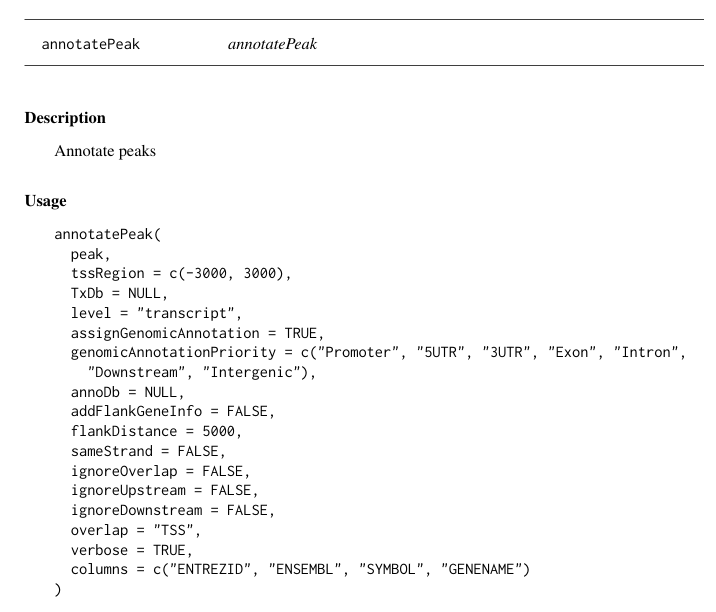

In [ ]:
genome_config <- list(
  hg38 = list(
    bsgenome = "BSgenome.Hsapiens.UCSC.hg38",
    txdb = "TxDb.Hsapiens.UCSC.hg38.knownGene"
  ),
  mm10 = list(
    bsgenome = "BSgenome.Mmusculus.UCSC.mm10",
    txdb = "TxDb.Mmusculus.UCSC.mm10.knownGene"
  )
)

for (ref in names(genome_config)) {
  cat("\n========== Processing", ref, "==========\n")
  config <- genome_config[[ref]]
  
  # Load libraries
  cat("Loading packages...\n")
  library(config$bsgenome, character.only = TRUE, quietly = TRUE)
  bs <- get(config$bsgenome, envir = asNamespace(config$bsgenome))
  
  library(config$txdb, character.only = TRUE, quietly = TRUE)
  txdb <- get(config$txdb, envir = asNamespace(config$txdb))
  
  # Filter chromosomes
  chr_list <- GenomeInfoDb::standardChromosomes(bs)
  chr_list <- chr_list[!tolower(chr_list) %in% c("mt", "chrm", "m", "mito")]
  txdb <- keepSeqlevels(txdb, chr_list, pruning.mode = "coarse")
  
  # Extract features
  cat("Extracting exons...\n")
  exon_gr <- exons(txdb)
  exon_gr$type <- "exon"

  cat("Extracting introns...\n")
  intron_list <- intronsByTranscript(txdb)
  if (length(intron_list) > 0) {
    intron_gr <- unlist(intron_list, use.names = TRUE)
    intron_gr$type <- "intron"
  } else {
    intron_gr <- GRanges()
  }

  cat("Extracting 5' UTRs...\n")
  utr5_list <- fiveUTRsByTranscript(txdb)
  if (length(utr5_list) > 0) {
    utr5_gr <- unlist(utr5_list, use.names = TRUE)
    utr5_gr$type <- "5' UTR"
  } else {
    utr5_gr <- GRanges()
  }

  cat("Extracting 3' UTRs...\n")
  utr3_list <- threeUTRsByTranscript(txdb)
  if (length(utr3_list) > 0) {
    utr3_gr <- unlist(utr3_list, use.names = TRUE)
    utr3_gr$type <- "3' UTR"
  } else {
    utr3_gr <- GRanges()
  }

  cat("Calculating promoters (TSS -1kb to TSS)...\n")
  transcript_gr <- transcripts(txdb)
  promoter_gr <- promoters(transcript_gr, upstream = 1000, downstream = 0)
  promoter_gr$type <- "promoter"

  # Merge and process
  cat("Merging features...\n")
  gr <- c(promoter_gr, utr5_gr, utr3_gr, exon_gr, intron_gr)
  gr <- gr[, "type", drop = FALSE]
  cat("Total features before priority annotation:", length(gr), "\n")
  cat("Feature counts:\n")
  print(table(gr$type))
  
  cat("Creating priority annotation...\n")
  gr_new <- create_priority_annotation(sort(gr))
  
  # Rename and capitalize
  colnames(mcols(gr_new)) <- "ccre_class" 
  gr_new$ccre_class <- sub("^([a-z])", "\\U\\1", gr_new$ccre_class, perl = TRUE)
  
  # Summary
  cat("Final annotation summary:\n")
  cat("Total regions:", length(gr_new), "\n")
  print(table(gr_new$ccre_class))
  
  # Save
  output_file <- glue::glue("knownGene_{ref}_processed.rds")
  saveRDS(gr_new, output_file, compress = "xz")
  cat("Saved to:", output_file, "\n")
}

========== Processing hg38 ==========
Extracting exons...  
Extracting introns...  
Extracting 5' UTRs...  
Extracting 3' UTRs...  
Calculating promoters (TSS -1kb to TSS)...  
Merging features...  
Total features before priority annotation: 2726037   
Feature counts:  
  
  3' UTR   5' UTR     exon   intron promoter   
  211648   175417   670382  1414557   254033   
Creating priority annotation...  
Final annotation summary:   
Total regions: 753688   

  3' UTR   5' UTR     Exon   Intron Promoter   
   74724    43964   267431   259301   108268   
Saved to: knownGene_hg38_processed.rds  
  
========== Processing mm10 ==========  
Loading packages...  
Extracting exons...  
Extracting introns...  
Extracting 5' UTRs...  
Extracting 3' UTRs...  
Calculating promoters (TSS -1kb to TSS)...  
Merging features...  
Total features before priority annotation: 1471036  
Feature counts:  
 
  3' UTR   5' UTR     exon   intron promoter  
   86993    95244   447230   699255   142314  
Creating priority annotation...  
Final annotation summary:  
Total regions: 624994  

  3' UTR   5' UTR     Exon   Intron Promoter   
   48506    35823   240606   218056    82003   
Saved to: knownGene_mm10_processed.rds   

In [ ]:
check_overlap(exon_gr, intron_gr)

Found 2433480 overlapping gene pairs


## Overview
**All GRanges object used in the annotation have no overlap inside.**  

  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/ChromHMM_hg38.rds   
No internal overlaps found  
  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/ChromHMM_mm10.rds  
No internal overlaps found  
  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/ENCODE_cCRE_v4_hg38.rds  
No internal overlaps found  
  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/ENCODE_cCRE_v4_mm10.rds  
No internal overlaps found  
  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/GENCODE_v49_hg38_processed.rds  
No internal overlaps found  
  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/GENCODE_vM23_mm10_processed.rds  
No internal overlaps found  
  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/knownGene_hg38_processed.rds  
No internal overlaps found  
  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/knownGene_mm10_processed.rds  
No internal overlaps found  
  
/dcs05/hongkai/data/next_cutntag/reference_data/rds/RepeatMasker_hg38_processed.rds  
No internal overlaps found  

/dcs05/hongkai/data/next_cutntag/reference_data/rds/RepeatMasker_mm10_processed.rds  
No internal overlaps found  